# Network Structure of Depressive Symptoms among U.S. Adults
### NHANES 2017 – March 2020 · Verification notebook

**Course:** CISC7204 Data Science and Data Visualization — Assignment 01, Preliminary Project Proposal
**Team:** ZHU ZHONGXIN (MC662722), DENG YI (MC662921)

**Research question.** *What is the network structure of depressive symptoms among U.S. adults, and how does it differ between physically active and inactive adults?*

The notebook first runs the conventional analysis pipeline (data wrangling, descriptive statistics, exploratory visualisation, group comparisons and a logistic regression), and then adds the network-analysis layer: a partial-correlation network of the nine PHQ-9 symptoms with centrality indices, and a subgroup comparison of the network between physically active and inactive adults.


## 0. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import networkx as nx

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', context='notebook')
np.random.seed(42)

DATA = 'data'
FIG  = 'figures'
os.makedirs(FIG, exist_ok=True)

# PHQ-9 item variable -> short symptom label
ITEMS  = ['DPQ010','DPQ020','DPQ030','DPQ040','DPQ050','DPQ060','DPQ070','DPQ080','DPQ090']
LABELS = {'DPQ010':'Anhedonia','DPQ020':'Sad mood','DPQ030':'Sleep',
          'DPQ040':'Fatigue','DPQ050':'Appetite','DPQ060':'Self-worth',
          'DPQ070':'Concentration','DPQ080':'Psychomotor','DPQ090':'Self-harm'}
SHORT  = [LABELS[i] for i in ITEMS]
print('pandas', pd.__version__, '| numpy', np.__version__, '| networkx', nx.__version__)

pandas 3.0.5 | numpy 2.5.2 | networkx 3.6.1


## 1. Import and merge the NHANES files
Four public-use files are joined on the respondent ID (`SEQN`): depression (DPQ), demographics (DEMO), body measures (BMX) and physical activity (PAQ). The official NHANES SAS-XPORT (.xpt) files have been converted to CSV, and this notebook reads the CSV copies.

In [2]:
dpq  = pd.read_csv(os.path.join(DATA,'DPQ_J.csv'))
demo = pd.read_csv(os.path.join(DATA,'DEMO_J.csv'))
bmx  = pd.read_csv(os.path.join(DATA,'BMX_J.csv'))
paq  = pd.read_csv(os.path.join(DATA,'PAQ_J.csv'))

df = (dpq[['SEQN']+ITEMS]
      .merge(demo[['SEQN','RIAGENDR','RIDAGEYR']], on='SEQN', how='inner')
      .merge(bmx[['SEQN','BMXBMI']],              on='SEQN', how='inner')
      .merge(paq[['SEQN','PAQ605','PAQ620']],     on='SEQN', how='inner'))
print('merged rows:', len(df))
df.head(3)

merged rows: 5533


,SEQN,DPQ010,DPQ020,DPQ030,DPQ040,DPQ050,DPQ060,DPQ070,DPQ080,DPQ090,RIAGENDR,RIDAGEYR,BMXBMI,PAQ605,PAQ620
0,93705.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,2.0,66.0,31.7,2.0,2.0
1,93706.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,1.0,18.0,21.5,2.0,2.0
2,93708.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,2.0,66.0,23.7,2.0,2.0


## 2. Data wrangling
Restrict to adults aged 20+ (the age at which the PHQ-9 is administered). Recode sex, derive a physically-active flag (any vigorous **or** moderate activity), and compute the PHQ-9 total with its standard severity bands.

In [3]:
df = df[(df['RIDAGEYR']>=20) & (df['RIDAGEYR']<=80)].copy()

# sex: 1 = Male, 2 = Female
df['Sex'] = df['RIAGENDR'].map({1:'Male',2:'Female'})

# physical activity: PAQ605 (vigorous) or PAQ620 (moderate) == 1 -> active
vig = df['PAQ605'].isin([1])
mod = df['PAQ620'].isin([1])
noact = df['PAQ605'].isin([2]) & df['PAQ620'].isin([2])
act = pd.Series(np.nan, index=df.index, dtype='object')
act[vig | mod] = 'Active'
act[noact] = 'Inactive'
df['Active'] = act

# PHQ-9 items are scored 0-9; keep numeric
for i in ITEMS:
    df[i] = pd.to_numeric(df[i], errors='coerce')

df['PHQ9_total'] = df[ITEMS].sum(axis=1, skipna=False)   # NaN if any item missing

def band(x):
    if pd.isna(x): return np.nan
    if x<=4:  return 'Minimal (0-4)'
    if x<=9:  return 'Mild (5-9)'
    if x<=14: return 'Moderate (10-14)'
    if x<=19: return 'Mod-severe (15-19)'
    return 'Severe (20-27)'
df['Severity'] = df['PHQ9_total'].apply(band)
df['Depressed'] = (df['PHQ9_total']>=10).astype('float')   # clinically relevant
df.loc[df['PHQ9_total'].isna(),'Depressed'] = np.nan

# BMI category
def bmi_cat(b):
    if pd.isna(b): return np.nan
    if b<18.5: return 'Underweight'
    if b<25:   return 'Normal'
    if b<30:   return 'Overweight'
    return 'Obese'
df['BMI_cat'] = df['BMXBMI'].apply(bmi_cat)

print('adults 20+:', len(df))
print('complete PHQ-9 cases:', int(df['PHQ9_total'].notna().sum()))
print('with activity + covariates:', int((df['PHQ9_total'].notna() & df['Active'].notna() & df['BMXBMI'].notna()).sum()))
df[['RIDAGEYR','BMXBMI','PHQ9_total']].describe().round(2)

adults 20+: 5265
complete PHQ-9 cases: 4846
with activity + covariates: 4788


,RIDAGEYR,BMXBMI,PHQ9_total
count,5265.00,5175.00,4846.00
mean,51.41,29.85,3.33
std,17.69,7.40,4.69
min,20.00,14.20,0.00
25%,36.00,24.80,0.00
50%,53.00,28.60,2.00
75%,65.00,33.60,5.00
max,80.00,86.20,72.00


## 3. Descriptive statistics
Sample profile, prevalence of each symptom (scoring "more than half the days", i.e. >= 2), and the distribution of severity bands.

In [4]:
prof = {
 'n (adults 20+, complete PHQ-9)': int(df['PHQ9_total'].notna().sum()),
 'mean age (years)': round(df['RIDAGEYR'].mean(),1),
 'female %': round(100*(df['Sex']=='Female').mean(),1),
 'physically active %': round(100*(df['Active']=='Active').mean(),1),
 'mean BMI': round(df['BMXBMI'].mean(),1),
 'mean PHQ-9 total': round(df['PHQ9_total'].mean(),2),
 'clinically relevant depression % (PHQ-9>=10)': round(100*df['Depressed'].mean(),1),
}
prof

{'n (adults 20+, complete PHQ-9)': 4846,
 'mean age (years)': np.float64(51.4),
 'female %': np.float64(51.7),
 'physically active %': np.float64(45.9),
 'mean BMI': np.float64(29.9),
 'mean PHQ-9 total': np.float64(3.33),
 'clinically relevant depression % (PHQ-9>=10)': np.float64(9.4)}

In [5]:
sym = pd.DataFrame({
    'Symptom': SHORT,
    'Mean score (0-9)': [round(df[i].mean(),2) for i in ITEMS],
    '% >= 2 (more than half the days)': [round(100*(df[i]>=2).mean(),1) for i in ITEMS],
}).sort_values('% >= 2 (more than half the days)', ascending=False)
sym

,Symptom,Mean score (0-9),% >= 2 (more than half the days)
3,Fatigue,0.76,16.3
2,Sleep,0.64,15.1
4,Appetite,0.40,9.2
0,Anhedonia,0.40,8.8
1,Sad mood,0.36,7.3
6,Concentration,0.27,6.0
5,Self-worth,0.26,5.0
7,Psychomotor,0.18,4.0
8,Self-harm,0.06,1.1


In [6]:
df['Severity'].value_counts(dropna=True).rename('n').to_frame().assign(
    percent = lambda t: (100*t['n']/t['n'].sum()).round(1))

,n,percent
Severity,,
Minimal (0-4),3590,74.1
Mild (5-9),801,16.5
Moderate (10-14),286,5.9
Mod-severe (15-19),120,2.5
Severe (20-27),49,1.0


## 4. Exploratory visualisation
Symptom prevalence, the PHQ-9 total distribution, depression score by activity and sex, and the item correlation heatmap that motivates the network model.

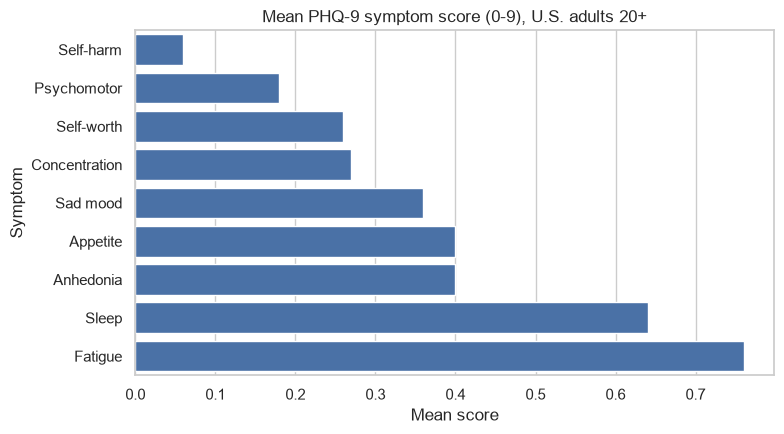

In [7]:
fig, ax = plt.subplots(figsize=(8,4.5))
order = sym.sort_values('Mean score (0-9)')
sns.barplot(x='Mean score (0-9)', y='Symptom', data=order, ax=ax, color='#3b6fb5')
ax.set_title('Mean PHQ-9 symptom score (0-9), U.S. adults 20+')
ax.set_xlabel('Mean score')
fig.tight_layout(); fig.savefig(os.path.join(FIG,'eda_symptom_prevalence.png'), dpi=150); plt.show()

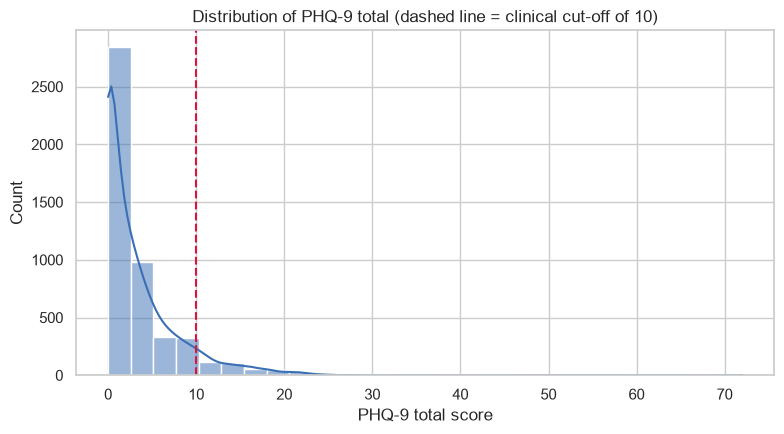

In [8]:
fig, ax = plt.subplots(figsize=(8,4.5))
sns.histplot(df['PHQ9_total'].dropna(), bins=28, kde=True, ax=ax, color='#3b6fb5')
ax.axvline(10, color='crimson', ls='--'); ax.set_title('Distribution of PHQ-9 total (dashed line = clinical cut-off of 10)')
ax.set_xlabel('PHQ-9 total score'); fig.tight_layout()
fig.savefig(os.path.join(FIG,'eda_phq9_distribution.png'), dpi=150); plt.show()

/var/folders/68/2mlcq61s21z1vyg5z__f9_8r0000gn/T/ipykernel_47645/3189088772.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Active', y='PHQ9_total', data=df.dropna(subset=['Active','PHQ9_total']), ax=axes[0], palette='Set2')
/var/folders/68/2mlcq61s21z1vyg5z__f9_8r0000gn/T/ipykernel_47645/3189088772.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Sex', y='PHQ9_total', data=df.dropna(subset=['PHQ9_total']), ax=axes[1], palette='Set2')


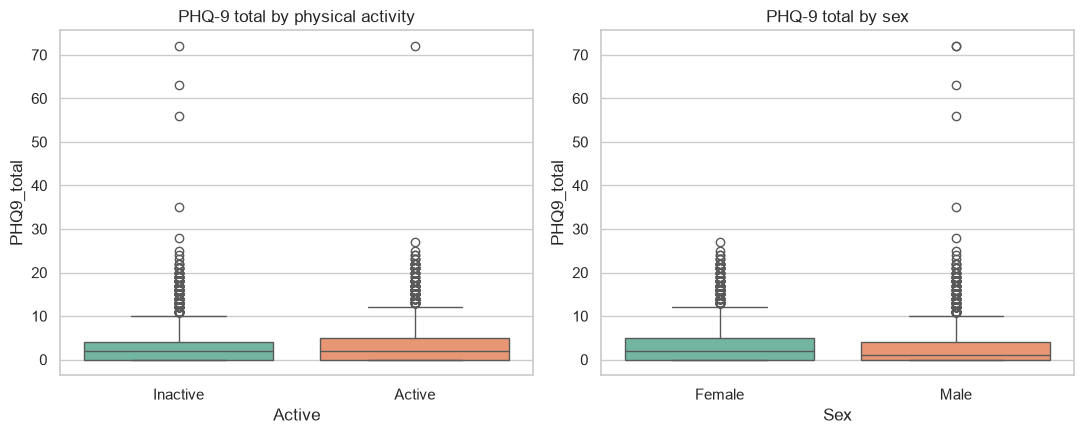

In [9]:
fig, axes = plt.subplots(1,2, figsize=(11,4.5))
sns.boxplot(x='Active', y='PHQ9_total', data=df.dropna(subset=['Active','PHQ9_total']), ax=axes[0], palette='Set2')
axes[0].set_title('PHQ-9 total by physical activity')
sns.boxplot(x='Sex', y='PHQ9_total', data=df.dropna(subset=['PHQ9_total']), ax=axes[1], palette='Set2')
axes[1].set_title('PHQ-9 total by sex')
fig.tight_layout(); fig.savefig(os.path.join(FIG,'eda_boxplot_activity_sex.png'), dpi=150); plt.show()

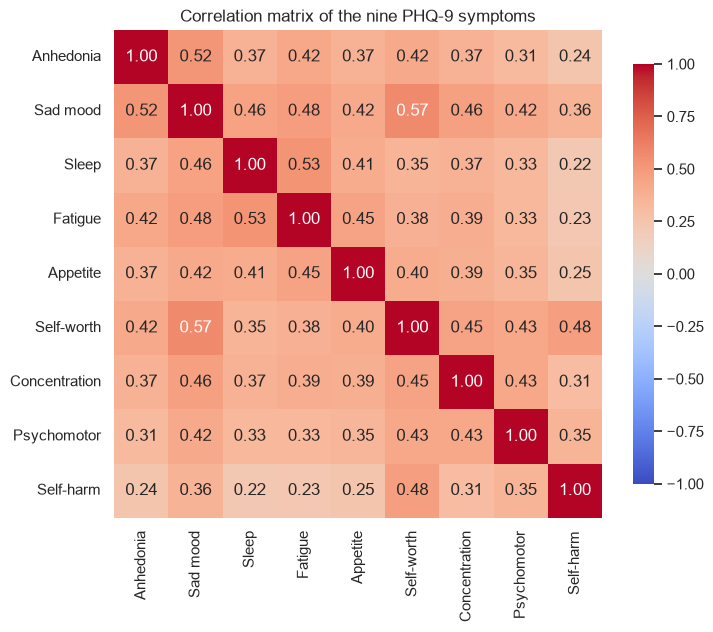

In [10]:
corr = df[ITEMS].corr()
corr.index = SHORT; corr.columns = SHORT
fig, ax = plt.subplots(figsize=(7.5,6.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={'shrink':0.8})
ax.set_title('Correlation matrix of the nine PHQ-9 symptoms')
fig.tight_layout(); fig.savefig(os.path.join(FIG,'eda_correlation_heatmap.png'), dpi=150); plt.show()

## 5. Group comparisons
Chi-square test of clinically relevant depression by activity, and t-tests of the PHQ-9 total by activity and by sex.

In [11]:
ct = pd.crosstab(df['Active'], df['Depressed'])
chi2, pchi, dof, _ = stats.chi2_contingency(ct)
print('Depression (PHQ-9>=10) x Activity  ->  chi2=%.2f, df=%d, p=%.4f' % (chi2, dof, pchi))
print(ct.assign(pct=lambda t: (100*t[1.0]/(t[0.0]+t[1.0])).round(1)))

Depression (PHQ-9>=10) x Activity  ->  chi2=2.44, df=1, p=0.1182
Depressed   0.0  1.0   pct
Active                    
Active     2052  231  10.1
Inactive   2332  224   8.8


In [12]:
a = df.loc[df['Active']=='Active','PHQ9_total'].dropna()
i = df.loc[df['Active']=='Inactive','PHQ9_total'].dropna()
t, pt = stats.ttest_ind(a, i, equal_var=False)
print('PHQ-9 total  Active(mean %.2f) vs Inactive(mean %.2f): t=%.2f, p=%.4g' % (a.mean(), i.mean(), t, pt))
m = df.loc[df['Sex']=='Male','PHQ9_total'].dropna(); f = df.loc[df['Sex']=='Female','PHQ9_total'].dropna()
t2, p2 = stats.ttest_ind(m, f, equal_var=False)
print('PHQ-9 total  Male(%.2f) vs Female(%.2f): t=%.2f, p=%.4g' % (m.mean(), f.mean(), t2, p2))

PHQ-9 total  Active(mean 3.53) vs Inactive(mean 3.15): t=2.79, p=0.005284
PHQ-9 total  Male(2.94) vs Female(3.71): t=-5.74, p=9.916e-09


## 6. Logistic regression
Model clinically relevant depression (PHQ-9 >= 10) on age, sex, BMI and physical activity. Odds ratios with 95% confidence intervals.

In [13]:
mdl_df = df.dropna(subset=['Depressed','RIDAGEYR','BMXBMI','Active']).copy()
mdl_df['female'] = (mdl_df['Sex']=='Female').astype(int)
mdl_df['active'] = (mdl_df['Active']=='Active').astype(int)
X = sm.add_constant(mdl_df[['RIDAGEYR','female','BMXBMI','active']].rename(columns={'RIDAGEYR':'age'}))
y = mdl_df['Depressed']
logit = sm.Logit(y, X).fit(disp=0)
res = pd.DataFrame({'OR': np.exp(logit.params),
                    'OR_lo95': np.exp(logit.conf_int()[0]),
                    'OR_hi95': np.exp(logit.conf_int()[1]),
                    'p': logit.pvalues}).round(3)
print('n =', len(mdl_df), ' pseudo-R2 =', round(logit.prsquared,3))
res

n = 4788  pseudo-R2 = 0.011


,OR,OR_lo95,OR_hi95,p
const,0.034,0.020,0.057,0.000
age,1.002,0.996,1.008,0.453
female,1.444,1.181,1.765,0.000
BMXBMI,1.023,1.011,1.035,0.000
active,1.245,1.019,1.520,0.032


## 7. Network analysis — partial-correlation network of the nine symptoms
The core layer. A Gaussian partial-correlation network is estimated on complete cases; each edge is the association between two symptoms given all the others. Edge colour: green = positive, red = negative; node size is proportional to *strength* centrality.

In [14]:
net_df = df[ITEMS].dropna()
print('complete cases for the network:', len(net_df))
R = np.corrcoef(net_df.values.T)
Rinv = np.linalg.inv(R)
d = np.sqrt(np.diag(Rinv))
pc = -Rinv / np.outer(d, d)          # partial correlation matrix
np.fill_diagonal(pc, 1.0)
pc = pd.DataFrame(pc, index=SHORT, columns=SHORT)

THRESH = 0.05                          # display edges with |partial r| above this
G = nx.Graph()
G.add_nodes_from(SHORT)
edges = []
for a in range(len(SHORT)):
    for b in range(a+1, len(SHORT)):
        w = pc.iloc[a,b]
        if abs(w) > THRESH:
            G.add_edge(SHORT[a], SHORT[b], weight=abs(w), sign=np.sign(w))
            edges.append((SHORT[a], SHORT[b], round(w,3)))
print('edges kept (|partial r| > %.2f): %d of %d possible' % (THRESH, G.number_of_edges(), len(SHORT)*(len(SHORT)-1)//2))
pd.DataFrame(edges, columns=['symptom_1','symptom_2','partial_r']).sort_values('partial_r', key=abs, ascending=False).head(10)

complete cases for the network: 4846
edges kept (|partial r| > 0.05): 28 of 36 possible


,symptom_1,symptom_2,partial_r
13,Sleep,Fatigue,0.313
24,Self-worth,Self-harm,0.292
9,Sad mood,Self-worth,0.274
0,Anhedonia,Sad mood,0.256
25,Concentration,Psychomotor,0.184
17,Fatigue,Appetite,0.179
7,Sad mood,Fatigue,0.147
27,Psychomotor,Self-harm,0.146
22,Self-worth,Concentration,0.129
2,Anhedonia,Fatigue,0.127


In [15]:
# centrality
strength = pc.abs().sum() - 1.0                       # exclude self
expected_influence = pc.sum() - 1.0                    # signed
centr = pd.DataFrame({'strength': strength.round(3),
                      'expected_influence': expected_influence.round(3)}).sort_values('strength', ascending=False)
print('Most central symptoms (by strength):')
centr

Most central symptoms (by strength):


,strength,expected_influence
Sad mood,1.123,1.123
Self-worth,1.046,1.046
Fatigue,0.920,0.891
Concentration,0.818,0.818
Sleep,0.784,0.784
Appetite,0.754,0.754
Psychomotor,0.753,0.753
Anhedonia,0.734,0.716
Self-harm,0.596,0.548


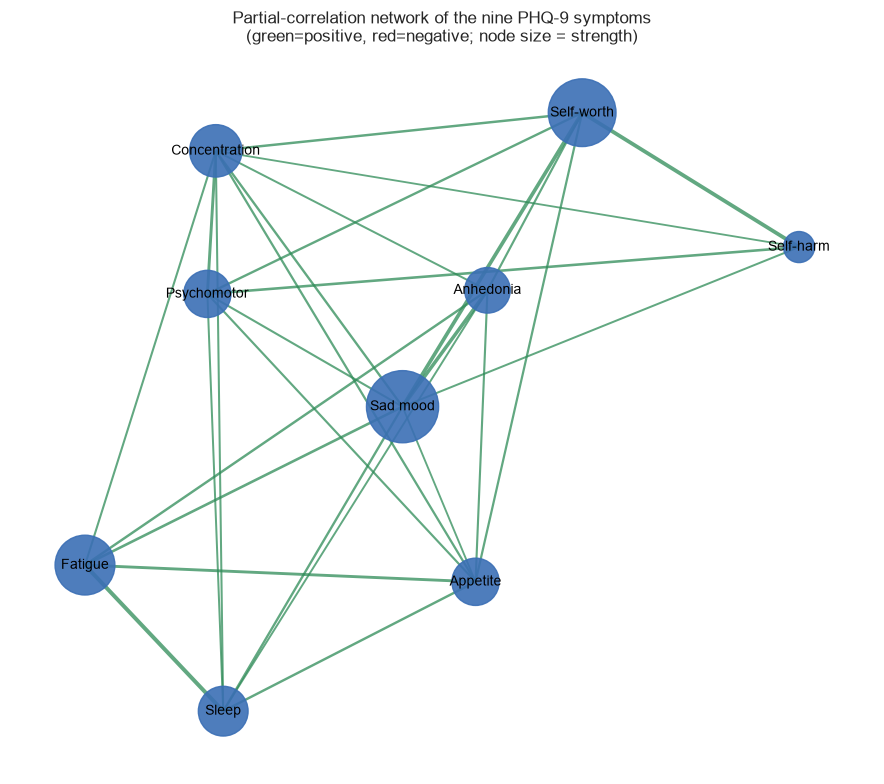

In [16]:
fig, ax = plt.subplots(figsize=(9,8))
pos = nx.spring_layout(G, seed=1, k=0.9)
node_size = 500 + 2200*(strength - strength.min())/(strength.max()-strength.min())
edge_colors  = ['#2e8b57' if s>0 else '#c0392b' for _,_,s in G.edges(data='sign')]
edge_widths  = [1 + 6*w for _,_,w in G.edges(data='weight')]
nx.draw_networkx_edges(G, pos, edge_color=edge_colors, width=edge_widths, alpha=.75, ax=ax)
nx.draw_networkx_nodes(G, pos, node_size=node_size, node_color='#3b6fb5', alpha=.9, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=10, font_color='black', ax=ax)
ax.set_title('Partial-correlation network of the nine PHQ-9 symptoms\n(green=positive, red=negative; node size = strength)')
ax.axis('off'); fig.tight_layout()
fig.savefig(os.path.join(FIG,'symptom-network.png'), dpi=170); plt.show()

## 8. Network comparison — physically active vs inactive adults
Global strength (the sum of all absolute edge weights) summarises how tightly the symptom system hangs together. We compare it between groups with a permutation test.

In [17]:
def global_strength(sub):
    R = np.corrcoef(sub.values.T); Ri = np.linalg.inv(R); dd = np.sqrt(np.diag(Ri))
    p = -Ri/np.outer(dd,dd); np.fill_diagonal(p,0)
    return np.abs(p).sum()

grp = df.dropna(subset=['Active'])[ITEMS+['Active']]
act = grp[grp['Active']=='Active'][ITEMS].dropna()
inact = grp[grp['Active']=='Inactive'][ITEMS].dropna()
obs = abs(global_strength(act) - global_strength(inact))
print('n active=%d (GS=%.2f), n inactive=%d (GS=%.2f), |diff|=%.2f'
      % (len(act), global_strength(act), len(inact), global_strength(inact), obs))

labels = np.array(['Active']*len(act) + ['Inactive']*len(inact))
pool = pd.concat([act, inact], ignore_index=True).values
perm = []
for _ in range(1000):
    idx = np.random.permutation(len(labels))
    g = labels[idx]
    a = pd.DataFrame(pool[g=='Active']); b = pd.DataFrame(pool[g=='Inactive'])
    perm.append(abs(global_strength(a) - global_strength(b)))
pval = (1+sum(1 for x in perm if x>=obs))/(1+len(perm))
print('Permutation test for difference in global strength: p = %.3f' % pval)
print('(p>0.05 => the two groups share a broadly similar symptom-network connectivity)')

n active=2283 (GS=7.57), n inactive=2556 (GS=7.61), |diff|=0.04


Permutation test for difference in global strength: p = 0.919
(p>0.05 => the two groups share a broadly similar symptom-network connectivity)


## 9. Summary of what the network shows
The most central symptoms and the strongest connections answer the research question directly: they reveal which depressive symptoms act as hubs in the U.S. adult population, and whether physical activity is associated with a differently connected symptom system.

In [18]:
print('Top central symptoms by strength:'); print(centr['strength'].head(3).round(2).to_string())
print('\nStrongest symptom pairs (partial r):')
print(pd.DataFrame(edges, columns=['a','b','pr']).sort_values('pr', key=abs, ascending=False).head(5).to_string(index=False))
print('\nKey descriptives: mean PHQ-9 total %.2f, clinically relevant depression %.1f%%, physically active %.1f%%'
      % (df['PHQ9_total'].mean(), 100*df['Depressed'].mean(), 100*(df['Active']=='Active').mean()))

Top central symptoms by strength:
Sad mood      1.12
Self-worth    1.05
Fatigue       0.92

Strongest symptom pairs (partial r):
            a           b    pr
        Sleep     Fatigue 0.313
   Self-worth   Self-harm 0.292
     Sad mood  Self-worth 0.274
    Anhedonia    Sad mood 0.256
Concentration Psychomotor 0.184

Key descriptives: mean PHQ-9 total 3.33, clinically relevant depression 9.4%, physically active 45.9%
